# HDD 03 — Baseline comparison
Run only after Notebook 02 completes. Use the same component folder and run ID.

Compare **Isolation Forest**, a **robust feature-deviation baseline**, and a **dense reconstruction autoencoder** using the identical 30-day windows. The first two consume 20 summary features; the autoencoder consumes flattened sequences, so the input difference must be stated when reporting results.

The robust baseline is a transparent statistical reference, **not a manufacturer SMART failure threshold**. Add independently justified SMART rules as a separate later baseline. No performance claim is precomputed here.

Only training, calibration and development data are loaded. The June test and real failure outcomes remain closed. Synthetic anomalies assess controlled sensitivity, not real failure recall or false-positive rates.


In [1]:
%pip -q install "numpy>=1.26,<3" "pandas>=2.2,<3" "scikit-learn>=1.4,<2" "pyarrow>=16" matplotlib joblib torch


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
from pathlib import Path
import json, hashlib, random, copy, time, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, joblib, torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import IsolationForest

COMPONENT_ROOT=Path('D:/SLIIT/Y4S1/RP/Research/J26-DS-342-/01_component_1_behavioral_drift_genai')  # EDIT
RUN_ID='single_model_q1q2_2021_v1'
RUN=COMPONENT_ROOT/'experiments'/RUN_ID
CONFIG_PATH=COMPONENT_ROOT/'config'/f'{RUN_ID}.json'
SPLIT_PATH=COMPONENT_ROOT/'data/splits'/f'{RUN_ID}_serials.json'
assert (RUN/'dataset_complete.json').exists(), 'Complete Notebook 02 first.'

def sha256(path):
    h=hashlib.sha256()
    with open(path,'rb') as handle:
        for block in iter(lambda:handle.read(1024*1024),b''): h.update(block)
    return h.hexdigest()

complete=json.loads((RUN/'dataset_complete.json').read_text())
assert complete['status']=='passed'
assert sha256(CONFIG_PATH)==complete['config_sha256']
assert sha256(SPLIT_PATH)==complete['split_sha256']
for relative,digest in complete['working_hashes'].items():
    assert sha256(COMPONENT_ROOT/relative)==digest, f'Changed input: {relative}'
cfg=json.loads(CONFIG_PATH.read_text())
FEATURES=cfg['raw_features']; WINDOW_DAYS=cfg['window_days']; SEED=cfg['seed']
FEATURE_ROOT=COMPONENT_ROOT/'data/features'/RUN_ID
OUT=COMPONENT_ROOT/'results'/RUN_ID/'baselines_v1'
MODELS=COMPONENT_ROOT/'models/trained'/RUN_ID/'baselines_v1'
OUT.mkdir(parents=True,exist_ok=True); MODELS.mkdir(parents=True,exist_ok=True)
raw,scaled,meta={},{},{}
for split in ['train','calibration','development']:
    folder=FEATURE_ROOT/split
    with np.load(folder/'windows_raw.npz') as data: raw[split]=data['X']
    with np.load(folder/'windows_scaled.npz') as data: scaled[split]=data['X']
    meta[split]=pd.read_parquet(folder/'metadata.parquet')
    assert len(raw[split])==len(meta[split]) and len(raw[split])>0
    print(split,raw[split].shape)
print('No sealed-test or failure-label file was loaded.')


train (42578, 30, 5)
calibration (4410, 30, 5)
development (4642, 30, 5)
No sealed-test or failure-label file was loaded.


## 1. Train summary-feature baselines
Use last value, median, standard deviation and net change for each of the five attributes. Apply the same `log1p` rule as the pilot before summarising. Summary-feature scaling is fitted on training data only.

The statistical score is the maximum absolute deviation from a training median, divided by training IQR (or 1 for a constant/sparse attribute). It is simple and label-free, but not a probabilistic score.


In [4]:
LOG_FEATURES=['smart_5_raw','smart_9_raw','smart_197_raw','smart_198_raw']
SUMMARY_NAMES=['last','median','std','net_change']
feature_names=[f'{feature}_{summary}' for summary in SUMMARY_NAMES for feature in FEATURES]

def summarise(X):
    values=X.astype(np.float64,copy=True)
    assert np.isfinite(values).all() and (values>=0).all()
    for feature in LOG_FEATURES:
        j=FEATURES.index(feature); values[...,j]=np.log1p(values[...,j])
    return np.concatenate([values[:,-1,:],np.median(values,axis=1),
        np.std(values,axis=1),values[:,-1,:]-values[:,0,:]],axis=1)

summary={s:summarise(x) for s,x in raw.items()}
summary_scaler=RobustScaler().fit(summary['train'])
Z={s:summary_scaler.transform(x) for s,x in summary.items()}
forest=IsolationForest(n_estimators=200,max_samples=256,contamination='auto',random_state=SEED,n_jobs=-1)
forest.fit(Z['train'])
score_tables={
    'isolation_forest':{s:-forest.score_samples(z) for s,z in Z.items()},
    'robust_deviation':{s:np.abs(z).max(axis=1) for s,z in Z.items()},
}
joblib.dump({'model':forest,'summary_scaler':summary_scaler,'feature_names':feature_names,
    'features':FEATURES,'log_features':LOG_FEATURES,'summary_names':SUMMARY_NAMES,
    'config_sha256':sha256(CONFIG_PATH)},MODELS/'tabular_baselines.joblib')
print('Tabular baselines fitted on training windows.')


Tabular baselines fitted on training windows.


## 2. Train a small dense autoencoder
This is an unsupervised reconstruction baseline. It is **not yet the proposed masked Transformer**.

Reserve 15% of the *training serials* for early stopping, with no serial overlap in the autoencoder's fit/stop subsets. Calibration remains reserved for score thresholds. Both training subsets are within the earlier training period; their shared preprocessing was fitted on the full training cohort, so the stopping loss is only an internal optimisation diagnostic, not an independent generalisation estimate.

The neural input is the flattened, train-scaled 30 × 5 window. No clipping is applied, so error spikes remain observable. If numerical checks fail, inspect the data/scaling rather than silently clipping anomalies away.


In [5]:
def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic=True
    torch.backends.cudnn.benchmark=False

seed_everything(SEED)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:',DEVICE)
train_serials=np.array(sorted(meta['train']['serial_number'].unique()))
np.random.default_rng(SEED+2).shuffle(train_serials)
n_stop=max(1,int(.15*len(train_serials)))
stop_ids=set(train_serials[:n_stop])
fit_selector=~meta['train']['serial_number'].isin(stop_ids).to_numpy()
stop_selector=~fit_selector
assert fit_selector.any() and stop_selector.any()
flat={s:x.reshape(len(x),-1).astype(np.float32) for s,x in scaled.items()}
INPUT_DIM=flat['train'].shape[1]

class DenseAutoencoder(nn.Module):
    def __init__(self,input_dim):
        super().__init__()
        self.encoder=nn.Sequential(nn.Linear(input_dim,64),nn.ReLU(),nn.Linear(64,16))
        self.decoder=nn.Sequential(nn.Linear(16,64),nn.ReLU(),nn.Linear(64,input_dim))
    def forward(self,x): return self.decoder(self.encoder(x))

network=DenseAutoencoder(INPUT_DIM).to(DEVICE)
optimizer=torch.optim.Adam(network.parameters(),lr=1e-3,weight_decay=1e-5)
generator=torch.Generator().manual_seed(SEED)
fit_loader=DataLoader(TensorDataset(torch.from_numpy(flat['train'][fit_selector])),batch_size=256,shuffle=True,generator=generator)
stop_loader=DataLoader(TensorDataset(torch.from_numpy(flat['train'][stop_selector])),batch_size=512)

def reconstruction_scores(values):
    network.eval(); scores=[]
    with torch.no_grad():
        for (batch,) in DataLoader(TensorDataset(torch.from_numpy(np.asarray(values,dtype=np.float32))),batch_size=512):
            batch=batch.to(DEVICE)
            error=(network(batch)-batch).square().mean(dim=1)
            if not torch.isfinite(error).all(): raise ValueError('Nonfinite neural score.')
            scores.append(error.cpu().numpy())
    return np.concatenate(scores)

MAX_EPOCHS=50; PATIENCE=7
best_loss=float('inf'); best_state=None; stale=0; history=[]
for epoch in range(1,MAX_EPOCHS+1):
    network.train(); total=0.; count=0
    for (batch,) in fit_loader:
        batch=batch.to(DEVICE); optimizer.zero_grad()
        loss=(network(batch)-batch).square().mean()
        if not torch.isfinite(loss): raise ValueError('Nonfinite training loss.')
        loss.backward(); nn.utils.clip_grad_norm_(network.parameters(),1.0); optimizer.step()
        total+=loss.item()*len(batch); count+=len(batch)
    stopping_loss=float(reconstruction_scores(flat['train'][stop_selector]).mean())
    history.append({'epoch':epoch,'fit_mse':total/count,'stopping_mse':stopping_loss})
    if stopping_loss < best_loss-1e-6:
        best_loss=stopping_loss; best_state=copy.deepcopy(network.state_dict()); stale=0
    else: stale+=1
    print(f'Epoch {epoch:02d} | fit {total/count:.5f} | stop {stopping_loss:.5f}')
    if stale>=PATIENCE: break
assert best_state is not None
network.load_state_dict(best_state)
score_tables['dense_autoencoder']={s:reconstruction_scores(x) for s,x in flat.items()}
pd.DataFrame(history).to_csv(OUT/'autoencoder_training_history.csv',index=False)
torch.save({'state_dict':{k:v.cpu() for k,v in best_state.items()},'input_dim':INPUT_DIM,
    'architecture':'150(or window_days*features)-64-16-64-input_dim','seed':SEED,
    'stopping_serials':sorted(stop_ids),'features':FEATURES,'window_days':WINDOW_DAYS,
    'config_sha256':sha256(CONFIG_PATH)},MODELS/'dense_autoencoder.pt')
print('Best checkpoint saved. Five-seed replication is a later research evaluation step.')


Device: cpu
Epoch 01 | fit 0.07551 | stop 0.00852
Epoch 02 | fit 0.00915 | stop 0.00765
Epoch 03 | fit 0.00840 | stop 0.00690
Epoch 04 | fit 0.00739 | stop 0.00622
Epoch 05 | fit 0.00691 | stop 0.00602
Epoch 06 | fit 0.00650 | stop 0.00571
Epoch 07 | fit 0.00594 | stop 0.00520
Epoch 08 | fit 0.00526 | stop 0.00450
Epoch 09 | fit 0.00471 | stop 0.00425
Epoch 10 | fit 0.00446 | stop 0.00409
Epoch 11 | fit 0.00432 | stop 0.00392
Epoch 12 | fit 0.00408 | stop 0.00370
Epoch 13 | fit 0.00387 | stop 0.00351
Epoch 14 | fit 0.00369 | stop 0.00338
Epoch 15 | fit 0.00350 | stop 0.00318
Epoch 16 | fit 0.00334 | stop 0.00315
Epoch 17 | fit 0.00336 | stop 0.00307
Epoch 18 | fit 0.00337 | stop 0.00334
Epoch 19 | fit 0.00347 | stop 0.00298
Epoch 20 | fit 0.00312 | stop 0.00295
Epoch 21 | fit 0.00306 | stop 0.00288
Epoch 22 | fit 0.00311 | stop 0.00286
Epoch 23 | fit 0.00320 | stop 0.00290
Epoch 24 | fit 0.00302 | stop 0.00278
Epoch 25 | fit 0.00290 | stop 0.00279
Epoch 26 | fit 0.00282 | stop 0.00270


## 3. Freeze one calibration threshold per detector
Use the April 99th score percentile as a pilot alert budget. This does not imply a 1% false-positive rate: April is unlabeled and overlapping windows are dependent. The proposal's final operational budget must be studied separately.

Raw scores differ in scale across detectors. Compare alert burden and controlled sensitivity rather than directly comparing raw score magnitudes.


In [6]:
QUANTILE=.99
thresholds={name:float(np.quantile(scores['calibration'],QUANTILE,method='higher'))
    for name,scores in score_tables.items()}
records=[]
for name,scores in score_tables.items():
    for split,values in scores.items():
        assert len(values)==len(meta[split]) and np.isfinite(values).all()
        table=meta[split].copy()
        table['anomaly_score']=values; table['threshold']=thresholds[name]
        table['is_anomaly_candidate']=values>thresholds[name]
        table.to_csv(OUT/f'{name}_{split}_scores.csv',index=False)
        records.append({'detector':name,'split':split,'windows':len(table),
            'drives_scored':table['serial_number'].nunique(),
            'flagged_windows':int(table['is_anomaly_candidate'].sum()),
            'flagged_percent':100*table['is_anomaly_candidate'].mean(),
            'drives_with_flags':table.loc[table['is_anomaly_candidate'],'serial_number'].nunique()})
summary_table=pd.DataFrame(records)
summary_table.to_csv(OUT/'alert_burden.csv',index=False)
(MODELS/'thresholds.json').write_text(json.dumps({'quantile':QUANTILE,'thresholds':thresholds},indent=2))
display(summary_table.round(3))


,detector,split,windows,drives_scored,flagged_windows,flagged_percent,drives_with_flags
0,isolation_forest,train,42578,700,743,1.745,33
1,isolation_forest,calibration,4410,147,44,0.998,4
2,isolation_forest,development,4642,150,35,0.754,2
3,robust_deviation,train,42578,700,179,0.420,23
4,robust_deviation,calibration,4410,147,44,0.998,2
5,robust_deviation,development,4642,150,0,0.000,0
6,dense_autoencoder,train,42578,700,247,0.580,19
7,dense_autoencoder,calibration,4410,147,44,0.998,3
8,dense_autoencoder,development,4642,150,31,0.668,1


## 4. Group consecutive flagged endpoints into alert events
Adjacent 30-day windows overlap heavily. Count consecutive flagged dates for the same drive as a single episode. This is descriptive grouping, not yet the final persistence rule. Later compare rules such as two consecutive candidates using development data only.


In [7]:
def alert_events(table):
    events=[]
    for serial,history in table.groupby('serial_number'):
        flags=history.loc[history['is_anomaly_candidate']].sort_values('end_date').copy()
        if flags.empty: continue
        flags['group']=flags['end_date'].diff().dt.days.ne(1).cumsum()
        for _,block in flags.groupby('group'):
            events.append({'serial_number':serial,'first_alert':block['end_date'].min(),
                'last_alert':block['end_date'].max(),'flagged_days':len(block),
                'maximum_score':block['anomaly_score'].max()})
    return pd.DataFrame(events,columns=['serial_number','first_alert','last_alert','flagged_days','maximum_score'])

for name,scores in score_tables.items():
    table=meta['development'].copy()
    table['anomaly_score']=scores['development']
    table['is_anomaly_candidate']=scores['development']>thresholds[name]
    events=alert_events(table)
    events.to_csv(OUT/f'{name}_development_events.csv',index=False)
    print(name,'development alert episodes:',len(events))


isolation_forest development alert episodes: 3
robust_deviation development alert episodes: 0
dense_autoencoder development alert episodes: 1


## 5. Controlled synthetic sensitivity
Inject each change into copies of development windows only. Do not retrain or recalibrate. These are independent **window perturbation tests**, not coherent fleet timelines, so do not calculate event recall or drift delay from them.

Use original below-threshold windows as the denominator for newly triggered alerts. Report the fraction of positive score changes and the increase in scores. Small physical shifts need not always be anomalous; the test shows detector response rather than proving correctness.

The correlation-break test permutes the final seven temperature readings within each window, disrupting alignment with the other attributes while preserving that segment's temperature values. It may have no effect on constant segments; log the number of windows actually changed.


In [8]:
development=raw['development']
temp=FEATURES.index('smart_194_raw')
synthetic={}
for amount in [2,5]:
    modified=development.copy(); modified[:,-7:,temp]+=amount
    synthetic[f'temperature_plus_{amount}_last_7_days']=modified
modified=development.copy(); modified[:,-1,temp]+=10
synthetic['temperature_spike_plus_10']=modified
modified=development.copy(); modified[:,-7:,temp]=modified[:,-8,temp][:,None]
synthetic['temperature_frozen_last_7_days']=modified
modified=development.copy(); rng=np.random.default_rng(SEED+3)
for row in range(len(modified)):
    modified[row,-7:,temp]=rng.permutation(modified[row,-7:,temp])
synthetic['temperature_alignment_break']=modified

prep=json.loads((COMPONENT_ROOT/'models/trained'/f'{RUN_ID}_daily_preprocessing.json').read_text())
assert prep['features']==FEATURES

def scale_daily(X):
    values=X.astype(np.float64,copy=True)
    for feature in prep['log_features']:
        j=FEATURES.index(feature); values[...,j]=np.log1p(values[...,j])
    return ((values-np.array(prep['center']))/np.array(prep['scale'])).astype(np.float32)

def score_all(X):
    z=summary_scaler.transform(summarise(X))
    sequence=scale_daily(X)
    return {'isolation_forest':-forest.score_samples(z),'robust_deviation':np.abs(z).max(axis=1),
        'dense_autoencoder':reconstruction_scores(sequence.reshape(len(sequence),-1))}

rows=[]
for experiment,X in synthetic.items():
    actually_changed=np.any(X!=development,axis=(1,2))
    for name,changed_scores in score_all(X).items():
        original=score_tables[name]['development']
        original_flag=original>thresholds[name]; changed_flag=changed_scores>thresholds[name]
        eligible=(~original_flag)&actually_changed
        newly=eligible&changed_flag
        rows.append({'experiment':experiment,'detector':name,'windows':len(X),
            'actually_changed_windows':int(actually_changed.sum()),
            'median_score_change':float(np.median(changed_scores-original)),
            'percent_score_increased':float(100*((changed_scores-original)>1e-10).mean()),
            'original_flagged':int(original_flag.sum()),'modified_flagged':int(changed_flag.sum()),
            'eligible_originally_unflagged_changed':int(eligible.sum()),'newly_flagged':int(newly.sum()),
            'new_alert_percent_of_eligible':float(100*newly.sum()/eligible.sum()) if eligible.any() else np.nan})
sensitivity=pd.DataFrame(rows)
sensitivity.to_csv(OUT/'synthetic_sensitivity.csv',index=False)
display(sensitivity.round(3))


,experiment,detector,windows,actually_changed_windows,median_score_change,percent_score_increased,original_flagged,modified_flagged,eligible_originally_unflagged_changed,newly_flagged,new_alert_percent_of_eligible
0,temperature_plus_2_last_7_days,isolation_forest,4642,4642,0.012,78.716,35,44,4607,9,0.195
1,temperature_plus_2_last_7_days,robust_deviation,4642,4642,0.286,69.647,0,0,4642,0,0.000
2,temperature_plus_2_last_7_days,dense_autoencoder,4642,4642,0.000,76.002,31,31,4611,0,0.000
3,temperature_plus_5_last_7_days,isolation_forest,4642,4642,0.063,95.993,35,75,4607,40,0.868
4,temperature_plus_5_last_7_days,robust_deviation,4642,4642,1.643,92.546,0,1,4642,1,0.022
5,temperature_plus_5_last_7_days,dense_autoencoder,4642,4642,0.001,96.833,31,31,4611,0,0.000
6,temperature_spike_plus_10,isolation_forest,4642,4642,0.102,99.612,35,118,4607,83,1.802
7,temperature_spike_plus_10,robust_deviation,4642,4642,4.143,97.243,0,67,4642,67,1.443
8,temperature_spike_plus_10,dense_autoencoder,4642,4642,0.004,99.871,31,31,4611,0,0.000
9,temperature_frozen_last_7_days,isolation_forest,4642,4460,0.000,47.393,35,35,4425,2,0.045


## 6. Plot and record the experiment
Do not choose a winner using synthetic sensitivity alone. Compare alert burden, event grouping, runtime, training stability, and response across perturbations. A model that alerts on everything is not useful.

Failure-based AUPRC, warning lead time, failure-event recall and false alerts require the later locked evaluation protocol. They are deliberately not calculated here.


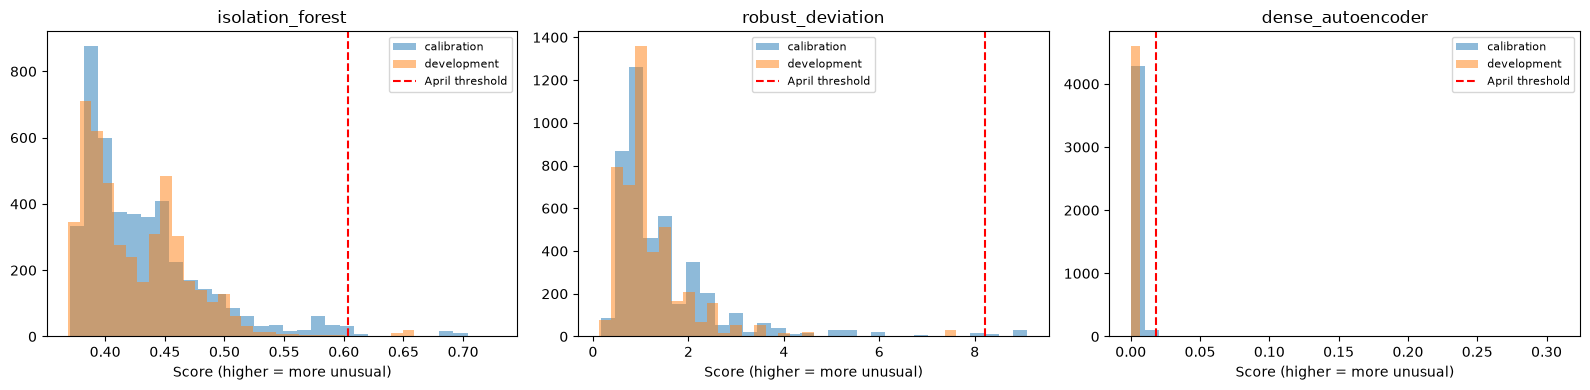

NOTEBOOK 03 COMPLETE. Save these outputs and write a short research-log interpretation.


In [9]:
fig,axes=plt.subplots(1,len(score_tables),figsize=(16,4))
for ax,(name,scores) in zip(axes,score_tables.items()):
    for split in ['calibration','development']:
        ax.hist(scores[split],bins=30,alpha=.5,label=split)
    ax.axvline(thresholds[name],color='red',linestyle='--',label='April threshold')
    ax.set_title(name); ax.set_xlabel('Score (higher = more unusual)'); ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT/'score_distributions.png',dpi=180,bbox_inches='tight')
plt.show()
log={
    'run_id':RUN_ID,'config_sha256':sha256(CONFIG_PATH),'seed':SEED,'quantile':QUANTILE,
    'versions':{'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,
                'sklearn':sklearn.__version__,'torch':torch.__version__},
    'neural_max_epochs':MAX_EPOCHS,'neural_epochs_completed':len(history),'early_stopping_patience':PATIENCE,
    'real_failure_labels_used':False,'sealed_test_opened':False,
    'limitations':['single HDD model','one training seed','dependent overlapping windows',
        'synthetic window sensitivity is not real failure detection',
        'statistical reference is not a manufacturer SMART-rule baseline',
        'autoencoder and tabular models use different representations'],
    'next_step':'HDD_04_Masked_SSL_Encoder.ipynb: compact masked temporal Transformer using the same saved windows',
}
(OUT/'experiment_record.json').write_text(json.dumps(log,indent=2))
print('NOTEBOOK 03 COMPLETE. Save these outputs and write a short research-log interpretation.')
